# 04 - Exploratory Data Analysis (EDA)

## Objective

The objective of this notebook is to explore the integrated solar plant dataset, understand power generation patterns, and analyze the relationship between solar power generation and weather conditions.

The findings will help us select suitable features for the solar power forecasting model.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the integrated dataset
df = pd.read_csv(
    "../data/processed/PS_001_integrated.csv",
    parse_dates=["datetime"]
)

In [3]:
df.head()

,datetime,ps_id,total_active_power_w,reporting_inverters,ghi_irradiance_wm2,poa_irradiance_wm2,ambient_temperature_celsius,panel_temperature_celsius,wind_speed_ms,id,...,number_of_panels,panel_area_mm2,panel_bifaciality_coefficient,panel_efficiency_percentage,panel_temperature_coefficient,structure_type,hour,day,month,day_of_week
0,2024-03-26 00:00:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,12062,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1
1,2024-03-26 00:15:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,12062,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1
2,2024-03-26 00:30:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,12062,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1
3,2024-03-26 00:45:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,12062,31516.36557,0.7,20.7,0.34,TRACKER,0,26,3,1
4,2024-03-26 01:00:00+00:00,PS_001,NaN,0,1.825104,2.076329,22.69768,21.249123,1.954988,PS_001,...,12062,31516.36557,0.7,20.7,0.34,TRACKER,1,26,3,1


In [4]:
df.shape

(26431, 23)

In [5]:
df.describe()

,total_active_power_w,reporting_inverters,ghi_irradiance_wm2,poa_irradiance_wm2,ambient_temperature_celsius,panel_temperature_celsius,wind_speed_ms,nominal_power_mw,number_of_panels,panel_area_mm2,panel_bifaciality_coefficient,panel_efficiency_percentage,panel_temperature_coefficient,hour,day,month,day_of_week
count,2.406100e+04,26431.000000,26431.000000,26431.000000,26431.000000,26431.000000,26431.000000,26431.0,26431.0,2.643100e+04,2.643100e+04,26431.0,2.643100e+04,26431.000000,26431.000000,26431.000000,26431.000000
mean,1.246015e+06,34.401839,202.049271,239.159510,23.236178,24.425224,2.127234,5.0,12062.0,3.151637e+04,7.000000e-01,20.7,3.400000e-01,11.490485,15.793803,7.815822,2.989104
std,1.683587e+06,11.304804,298.341420,341.592395,5.243541,9.667878,1.274601,0.0,0.0,3.638048e-12,1.110244e-16,0.0,5.551220e-17,6.924252,8.824810,2.613040,1.996107
min,0.000000e+00,0.000000,0.000000,0.000000,6.900000,3.442096,-0.265144,5.0,12062.0,3.151637e+04,7.000000e-01,20.7,3.400000e-01,0.000000,1.000000,3.000000,0.000000
25%,0.000000e+00,37.000000,0.000000,0.000000,19.799999,17.731406,1.214874,5.0,12062.0,3.151637e+04,7.000000e-01,20.7,3.400000e-01,5.000000,8.000000,6.000000,1.000000
50%,9.698808e+03,39.000000,1.825104,2.076329,22.697680,21.249123,1.957898,5.0,12062.0,3.151637e+04,7.000000e-01,20.7,3.400000e-01,11.000000,16.000000,8.000000,3.000000
75%,2.796084e+06,40.000000,367.989352,512.065554,27.100000,30.543527,2.839980,5.0,12062.0,3.151637e+04,7.000000e-01,20.7,3.400000e-01,17.000000,23.000000,10.000000,5.000000
max,5.039596e+06,40.000000,1313.049358,1365.207119,38.233577,58.785002,9.237250,5.0,12062.0,3.151637e+04,7.000000e-01,20.7,3.400000e-01,23.000000,31.000000,12.000000,6.000000


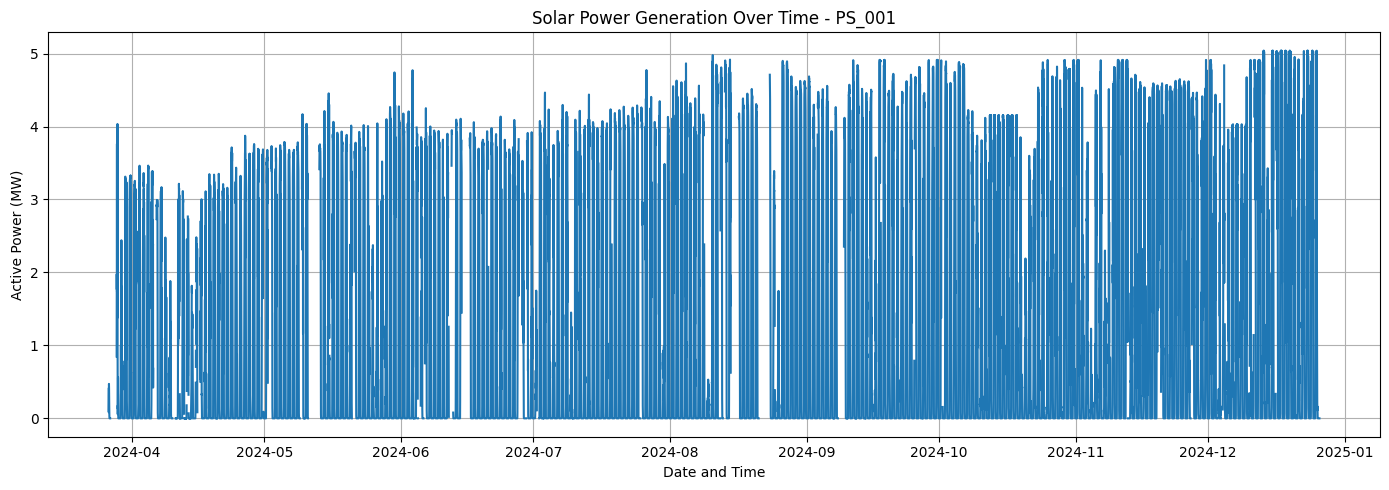

In [6]:
#Graph solar power generation over time
df = df.sort_values("datetime")

plt.figure(figsize=(14,5))

plt.plot(df["datetime"] , df["total_active_power_w"]/ 1000000)

plt.title("Solar Power Generation Over Time - PS_001")
plt.xlabel("Date and Time")
plt.ylabel("Active Power (MW)")
plt.grid(True)
plt.tight_layout()
plt.show()

#Your power values are in watts (W). Dividing by one million converts watts to megawatts (MW), making the graph easier to read.

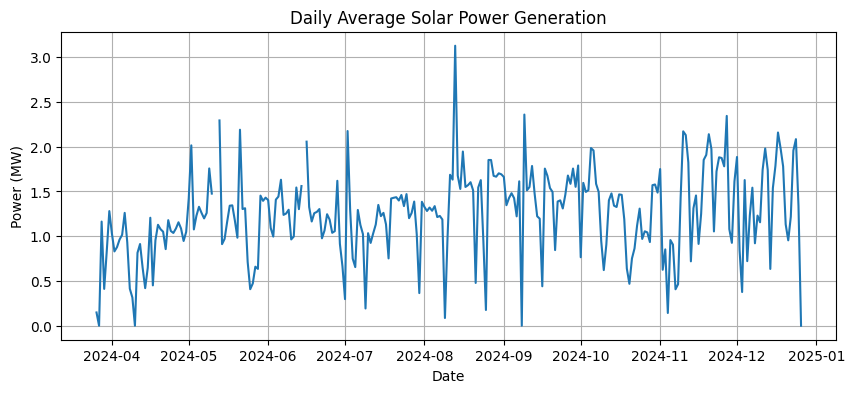

In [7]:
daily_power = df.resample("D", on="datetime")["total_active_power_w"].mean()

plt.figure(figsize=(10,4))

plt.plot(daily_power.index, daily_power/ 1000000)

plt.title("Daily Average Solar Power Generation")
plt.xlabel("Date")
plt.ylabel("Power (MW)")
plt.grid()
plt.show()


### Insight: Daily Average Solar Power Generation

The graph shows that daily average solar power generation at plant PS_001 varies throughout the observed period from March to December 2024.

Most daily averages appear to fall around 1–2 MW, although some days have much lower or higher values. A noticeable peak occurs in August, while several sharp drops appear across different months.

These variations may be related to weather conditions, plant operation, or incomplete power measurements. Further analysis of solar irradiance and data quality is required before determining the causes.

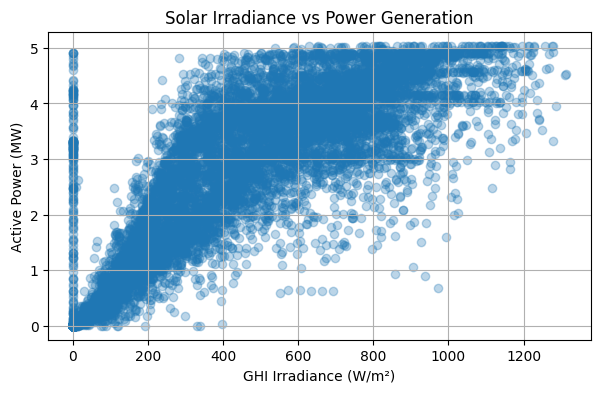

In [8]:
#Compare irradiance with power generation
plt.figure(figsize=(7, 4))

plt.scatter(
    df["ghi_irradiance_wm2"],
    df["total_active_power_w"] / 1000000,
    alpha=0.3
)

plt.title("Solar Irradiance vs Power Generation")
plt.xlabel("GHI Irradiance (W/m²)")
plt.ylabel("Active Power (MW)")
plt.grid()
plt.show()

### Insight: Solar Irradiance vs Power Generation

The scatter plot shows a generally positive relationship between GHI irradiance and recorded active power. Power output tends to increase as sunlight becomes stronger and often approaches the plant's approximate 5 MW nominal capacity.

However, power output varies at similar irradiance levels. Some observations also show high power when GHI is zero, which requires further investigation for possible data-quality or timestamp-alignment issues.

Therefore, GHI appears to be a useful feature for solar power forecasting, but additional data-quality checks are needed before model training.

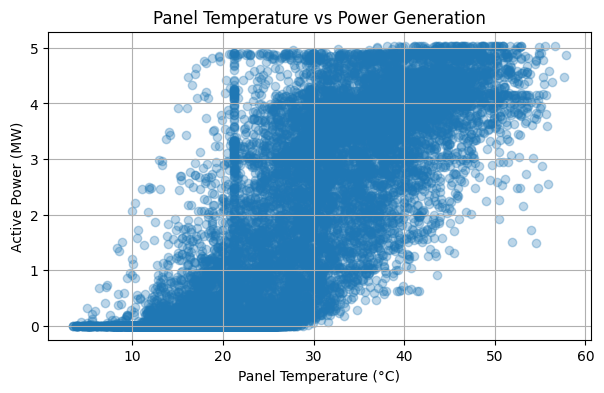

In [9]:
#Compare panel temperature with power
plt.figure(figsize=(7, 4))

plt.scatter(
    df["panel_temperature_celsius"],
    df["total_active_power_w"] / 1000000,
    alpha=0.3
)

plt.title("Panel Temperature vs Power Generation")
plt.xlabel("Panel Temperature (°C)")
plt.ylabel("Active Power (MW)")
plt.grid()
plt.show()

### Insight: Panel Temperature vs Power Generation

The scatter plot shows that power generation varies considerably across different panel temperatures. Higher power readings are frequently observed at warmer panel temperatures, but this does not establish a direct causal relationship because sunlight also affects panel temperature and power output.

At similar temperatures, power generation varies widely, indicating that panel temperature alone is insufficient to explain the recorded output. Other factors, such as solar irradiance and plant operating conditions, should also be considered.

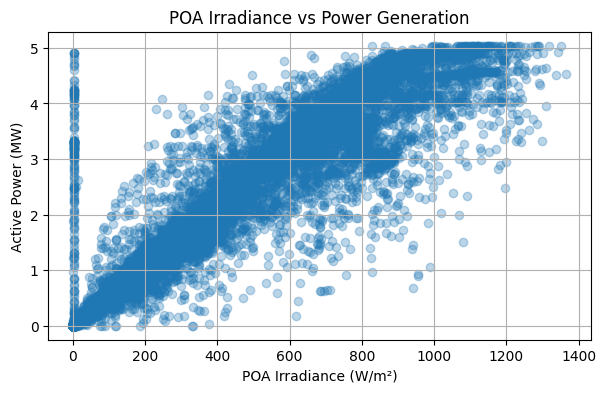

In [10]:
#POA Irradiance vs Power Generation
plt.figure(figsize=(7, 4))

plt.scatter(
    df["poa_irradiance_wm2"],
    df["total_active_power_w"] / 1000000,
    alpha=0.3
)

plt.title("POA Irradiance vs Power Generation")
plt.xlabel("POA Irradiance (W/m²)")
plt.ylabel("Active Power (MW)")
plt.grid()
plt.show()

### Insight: POA Irradiance vs Power Generation

The scatter plot shows a positive relationship between POA irradiance and recorded active power. Power output generally increases as the sunlight received by the panels increases, with many readings approaching 5 MW at higher irradiance levels.

However, power generation varies at similar irradiance levels, indicating that other factors may influence the recorded output. Some observations also show high power at zero irradiance, which requires further data-quality investigation before model training.

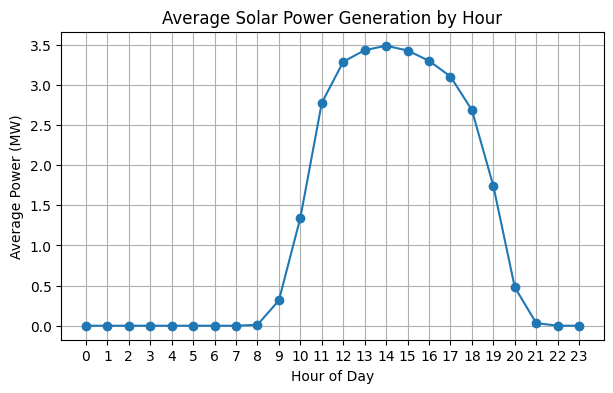

In [11]:
#Average Power Generation by Hour
hourly_power = df.groupby("hour")["total_active_power_w"].mean()

plt.figure(figsize=(7, 4))
plt.plot(hourly_power.index, hourly_power / 1000000, marker="o")

plt.title("Average Solar Power Generation by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power (MW)")
plt.xticks(range(0, 24))
plt.grid()
plt.show()

### Insight: Average Solar Power Generation by Hour

The hourly analysis shows that recorded solar power generation is nearly zero overnight, begins increasing in the morning, and reaches its highest average of approximately 3.5 MW around 2 PM UTC. Generation then decreases during the evening.

This pattern is consistent with the availability of sunlight throughout the day. The results represent average recorded power for each hour across the available dataset. Since the timestamps are in UTC, local-time interpretation requires converting the timestamps to the plant's local time zone.

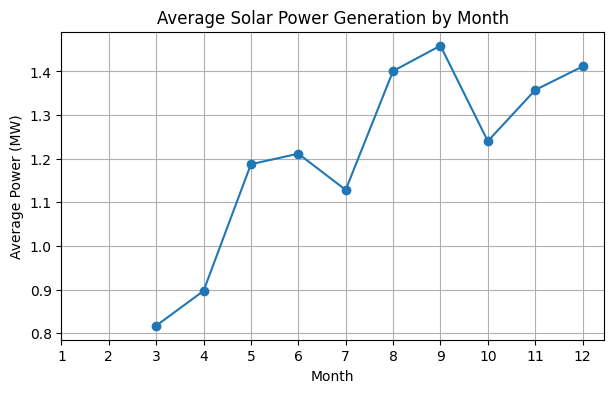

In [12]:
#Average Power Generation by Month
monthly_power = df.groupby("month")["total_active_power_w"].mean()

plt.figure(figsize=(7, 4))
plt.plot(monthly_power.index, monthly_power / 1000000, marker="o")

plt.title("Average Solar Power Generation by Month")
plt.xlabel("Month")
plt.ylabel("Average Power (MW)")
plt.xticks(range(1, 13))
plt.grid()
plt.show()


### Insight: Average Solar Power Generation by Month

The monthly analysis shows that average recorded solar power generation generally increases from March to May, decreases slightly in July, and rises again in August and September. September has the highest average recorded power at approximately 1.46 MW. Generation decreases in October before recovering in November and December.

These results show month-to-month variation in recorded power output. Further analysis of weather conditions and data quality is needed to understand the reasons for these changes.

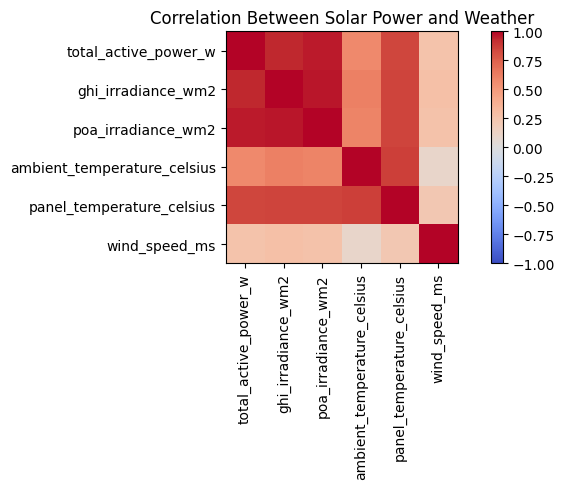

In [13]:
#Correlation Analysis between Numerical Features

columns = [
    "total_active_power_w",
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "ambient_temperature_celsius",
    "panel_temperature_celsius",
    "wind_speed_ms"
]

correlation = df[columns].corr()

plt.figure(figsize=(8, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(range(len(columns)), columns, rotation=90)
plt.yticks(range(len(columns)), columns)

plt.colorbar()
plt.title("Correlation Between Solar Power and Weather")
plt.tight_layout()
plt.show()

### Insight: Correlation Analysis

The correlation heatmap shows strong positive relationships between solar irradiance measurements (GHI and POA) and recorded active power. This suggests that irradiance is an important feature for solar power forecasting.

GHI and POA are also strongly correlated with each other because both represent measures of available sunlight. Panel temperature shows a positive relationship with power, while wind speed appears to have a weaker relationship.

Correlation indicates association, not causation. These findings will help guide feature selection for the forecasting model.

## Find unusual records

In [14]:
unusual_data = df[
    (df["ghi_irradiance_wm2"] == 0) &
    (df["total_active_power_w"] > 1000000)
]

unusual_data[
    [
        "datetime",
        "ghi_irradiance_wm2",
        "poa_irradiance_wm2",
        "total_active_power_w",
        "reporting_inverters"
    ]
].head(10)

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2,total_active_power_w,reporting_inverters
14340,2024-08-22 09:00:00+00:00,0.0,0.0,1877992.0,40
14435,2024-08-23 08:45:00+00:00,0.0,0.0,1223472.0,40


In [15]:
#Check nearby readings
check_data = df[
    (df["datetime"] >= "2024-08-22 08:00:00+00:00") &
    (df["datetime"] <= "2024-08-22 10:00:00+00:00")
]

check_data[
    [
        "datetime",
        "ghi_irradiance_wm2",
        "poa_irradiance_wm2",
        "total_active_power_w",
        "reporting_inverters"
    ]
]

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2,total_active_power_w,reporting_inverters
14336,2024-08-22 08:00:00+00:00,0.000000,0.000000,NaN,0
14337,2024-08-22 08:15:00+00:00,0.000000,0.000000,NaN,0
14338,2024-08-22 08:30:00+00:00,0.000000,0.000000,NaN,0
14339,2024-08-22 08:45:00+00:00,0.000000,0.000000,NaN,0
14340,2024-08-22 09:00:00+00:00,0.000000,0.000000,1877992.0,40
14341,2024-08-22 09:15:00+00:00,0.000000,0.000000,NaN,0
14342,2024-08-22 09:30:00+00:00,2.058653,2.615144,NaN,0
14343,2024-08-22 09:45:00+00:00,20.347925,23.154053,NaN,0
14344,2024-08-22 10:00:00+00:00,52.330002,76.769997,NaN,0


Finding 1: Missing inverter readings

Most timestamps have zero reporting inverters and missing power values. This means no valid inverter power readings were available at those timestamps.

Finding 2: One unusual power reading

At 09:00, all 40 inverters reported power, giving a combined value of 1.88 MW, even though both GHI and POA were zero.

Finding 3: Weather measurements start increasing

At 09:30 and afterward, irradiance starts increasing, which is consistent with sunlight becoming available.

Finding 4: The unusual reading may be unreliable

The 09:00 reading could be a data-quality issue or a timestamp alignment issue. We cannot confirm the cause from these rows alone.

### Investigation of Unusual Zero-Irradiance Readings

During data-quality investigation, I identified an unusual observation on 22 August 2024 at 09:00 UTC. The plant recorded approximately 1.88 MW of active power while both GHI and POA irradiance were zero.

The surrounding records showed missing inverter power measurements at most timestamps, while irradiance began increasing after 09:15 UTC.

This observation was flagged for further investigation rather than removed immediately because the available data does not establish the exact cause.

In [16]:
inverter = pd.read_csv(
    "../data/raw/BR-PVGen_inverter/PS_001.csv"
)

inverter["datetime"] = pd.to_datetime(
    inverter["datetime"], utc=True
)

In [17]:
#Check the original inverter readings
raw_check = inverter[
    (inverter["datetime"] == "2024-08-22 09:00:00+00:00")
]

raw_check[
    ["datetime", "inverter_id", "total_active_power_w"]
]


,datetime,inverter_id,total_active_power_w
568320,2024-08-22 09:00:00+00:00,1,0.0
568321,2024-08-22 09:00:00+00:00,2,677.0
568322,2024-08-22 09:00:00+00:00,3,0.0
568323,2024-08-22 09:00:00+00:00,4,0.0
568324,2024-08-22 09:00:00+00:00,5,1302.0
568325,2024-08-22 09:00:00+00:00,6,0.0
568326,2024-08-22 09:00:00+00:00,7,0.0
568327,2024-08-22 09:00:00+00:00,8,0.0
568328,2024-08-22 09:00:00+00:00,9,1976.0
568329,2024-08-22 09:00:00+00:00,10,3443.0


In [19]:

weather = pd.read_csv(
    "../data/processed/PS_001_weather_clean.csv"
)

weather["datetime"] = pd.to_datetime(
    weather["datetime"], utc=True
)

In [20]:
weather.columns.tolist()

['datetime',
 'ps_id',
 'ghi_irradiance_wm2',
 'poa_irradiance_wm2',
 'ambient_temperature_celsius',
 'panel_temperature_celsius',
 'wind_speed_ms']

the unusual reading was already present in the original datasets. It was not caused by our cleaning or aggregation code.

### Data Quality Investigation: Zero Irradiance with High Power

An unusual observation was identified on 22 August 2024 at 09:00 UTC. The inverter dataset recorded approximately 1.88 MW of active power across 40 reporting inverters, while both GHI and POA irradiance were recorded as zero.

The same values were found in the original raw datasets, confirming that this mismatch was not introduced during data cleaning or integration.

The observation was flagged for further investigation. It was not removed because the exact cause could not be confirmed from the available data.

## second unusual observation: 23 August 2024, 08:45 UTC

In [22]:
raw_weather = pd.read_csv("../data/processed/PS_001_weather_clean.csv")

raw_weather["datetime"] = pd.to_datetime(
    raw_weather["datetime"], utc=True
)

weather_check_2 = raw_weather[
    raw_weather["datetime"] == "2024-08-23 08:45:00+00:00"
]

weather_check_2[
    ["datetime", "ghi_irradiance_wm2", "poa_irradiance_wm2"]
]

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2
14435,2024-08-23 08:45:00+00:00,0.0,0.0


In [23]:
df[
    (df["datetime"] >= "2024-08-23 07:45:00+00:00") &
    (df["datetime"] <= "2024-08-23 09:45:00+00:00")
][
    ["datetime", "ghi_irradiance_wm2", "poa_irradiance_wm2",
     "total_active_power_w", "reporting_inverters"]
]

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2,total_active_power_w,reporting_inverters
14431,2024-08-23 07:45:00+00:00,0.000000,0.000000,NaN,0
14432,2024-08-23 08:00:00+00:00,0.000000,0.000000,NaN,0
14433,2024-08-23 08:15:00+00:00,0.000000,0.000000,NaN,0
14434,2024-08-23 08:30:00+00:00,0.000000,0.000000,NaN,0
14435,2024-08-23 08:45:00+00:00,0.000000,0.000000,1223472.0,40
14436,2024-08-23 09:00:00+00:00,0.000000,0.000000,NaN,0
14437,2024-08-23 09:15:00+00:00,0.000000,0.000000,NaN,0
14438,2024-08-23 09:30:00+00:00,2.386738,3.321771,NaN,0
14439,2024-08-23 09:45:00+00:00,17.049999,18.480000,NaN,0


In [24]:
#Check interpolation and measurement counts
raw_weather_full["datetime"] = pd.to_datetime(
    raw_weather_full["datetime"], utc=True
)

timestamps = [
    "2024-08-22 09:00:00+00:00",
    "2024-08-23 08:45:00+00:00"
]

weather_quality = raw_weather_full[
    raw_weather_full["datetime"].isin(timestamps)
]

weather_quality[[
    "datetime",
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "document_count_ghi_irradiance_wm2",
    "document_count_poa_irradiance_wm2",
    "interpolated_keys_ghi_irradiance_wm2",
    "interpolated_keys_poa_irradiance_wm2"
]]

NameError: name 'raw_weather_full' is not defined

In [25]:
print(raw_weather.columns.tolist())

['datetime', 'ps_id', 'ghi_irradiance_wm2', 'poa_irradiance_wm2', 'ambient_temperature_celsius', 'panel_temperature_celsius', 'wind_speed_ms']


In [26]:
raw_weather_full = pd.read_csv(
    "../data/raw/BR-PVGen_meteorological/PS_001.csv"
)

print(raw_weather_full.columns.tolist())

['ambient_temperature_celsius', 'battery_voltage', 'datetime', 'document_count_ambient_temperature_celsius', 'document_count_battery_voltage', 'document_count_ghi_irradiance_wm2', 'document_count_gri_irradiance_wm2', 'document_count_panel_temperature_celsius', 'document_count_poa_irradiance_wm2', 'document_count_precipitation_accumulated_mm', 'document_count_tracker_albedo_index', 'document_count_wind_direction_degrees', 'document_count_wind_speed_ms', 'ghi_irradiance_wm2', 'gri_irradiance_wm2', 'interpolated_keys_ambient_temperature_celsius', 'interpolated_keys_battery_voltage', 'interpolated_keys_ghi_irradiance_wm2', 'interpolated_keys_gri_irradiance_wm2', 'interpolated_keys_panel_temperature_celsius', 'interpolated_keys_poa_irradiance_wm2', 'interpolated_keys_tracker_albedo_index', 'interpolated_keys_wind_direction_degrees', 'interpolated_keys_wind_speed_ms', 'panel_temperature_celsius', 'poa_irradiance_wm2', 'precipitation_accumulated_mm', 'ps_id', 'tracker_albedo_index', 'wind_dir

In [27]:
raw_weather_full[
    (raw_weather_full["datetime"] >= "2024-08-22 08:00:00+00:00") &
    (raw_weather_full["datetime"] <= "2024-08-22 10:00:00+00:00")
][[
    "datetime",
    "ghi_irradiance_wm2",
    "poa_irradiance_wm2",
    "document_count_ghi_irradiance_wm2",
    "document_count_poa_irradiance_wm2"
]]

,datetime,ghi_irradiance_wm2,poa_irradiance_wm2,document_count_ghi_irradiance_wm2,document_count_poa_irradiance_wm2


In [28]:
inverter_quality = inverter[
    inverter["datetime"] == "2024-08-22 09:00:00+00:00"
]

inverter_quality[[
    "datetime",
    "inverter_id",
    "total_active_power_w",
    "document_count_total_active_power_w",
    "interpolated_keys_total_active_power_w"
]].head(10)

,datetime,inverter_id,total_active_power_w,document_count_total_active_power_w,interpolated_keys_total_active_power_w
568320,2024-08-22 09:00:00+00:00,1,0.0,1,NaN
568321,2024-08-22 09:00:00+00:00,2,677.0,1,NaN
568322,2024-08-22 09:00:00+00:00,3,0.0,1,NaN
568323,2024-08-22 09:00:00+00:00,4,0.0,1,NaN
568324,2024-08-22 09:00:00+00:00,5,1302.0,1,NaN
568325,2024-08-22 09:00:00+00:00,6,0.0,1,NaN
568326,2024-08-22 09:00:00+00:00,7,0.0,1,NaN
568327,2024-08-22 09:00:00+00:00,8,0.0,1,NaN
568328,2024-08-22 09:00:00+00:00,9,1976.0,1,NaN
568329,2024-08-22 09:00:00+00:00,10,3443.0,1,NaN


In [29]:
inverter_quality[[
    "document_count_total_active_power_w",
    "interpolated_keys_total_active_power_w"
]].value_counts(dropna=False)

document_count_total_active_power_w  interpolated_keys_total_active_power_w
1                                    NaN                                       40
Name: count, dtype: int64

In [30]:
inverter_quality_2 = inverter[
    inverter["datetime"] == "2024-08-23 08:45:00+00:00"
]

inverter_quality_2[
    [
        "document_count_total_active_power_w",
        "interpolated_keys_total_active_power_w"
    ]
].value_counts(dropna=False)

document_count_total_active_power_w  interpolated_keys_total_active_power_w
1                                    NaN                                       40
Name: count, dtype: int64

### Create an anomaly flag

In [31]:
df["anomaly_flag"] = 0

unusual_timestamps = [
    "2024-08-22 09:00:00+00:00",
    "2024-08-23 08:45:00+00:00"
]

df.loc[
    df["datetime"].isin(pd.to_datetime(unusual_timestamps, utc=True)),
    "anomaly_flag"
] = 1

In [32]:
df[df["anomaly_flag"] == 1][
    ["datetime", "total_active_power_w", "anomaly_flag"]
]

,datetime,total_active_power_w,anomaly_flag
14340,2024-08-22 09:00:00+00:00,1877992.0,1
14435,2024-08-23 08:45:00+00:00,1223472.0,1


In [33]:
df.to_csv(
    "../data/processed/PS_001_integrated_flagged.csv",
    index=False
)